In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training data:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing data :", x_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data: (60000, 28, 28)
Training labels: (60000,)
Testing data : (10000, 28, 28)
Testing labels: (10000,)


In [ ]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Training shape:", x_train.shape)
print("Testing shape :", x_test.shape)

Training shape: (60000, 784)
Testing shape : (10000, 784)


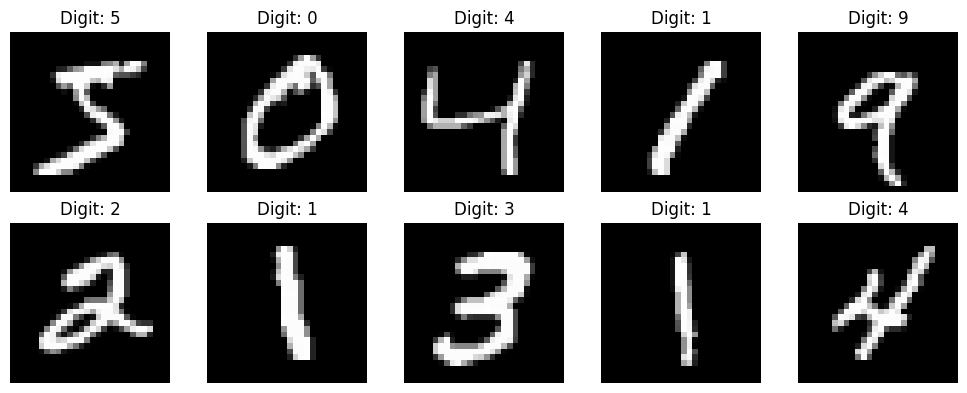

In [ ]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def create_model(activation):

    model = tf.keras.Sequential([
        layers.Input(shape=(784,)),

        layers.Dense(128, activation=activation),

        layers.Dense(64, activation=activation),

        layers.Dense(10, activation="softmax")
    ])

    return model

In [ ]:
model_sigmoid = create_model("sigmoid")
model_tanh = create_model("tanh")
model_relu = create_model("relu")

In [ ]:
print("SIGMOID MODEL")
model_sigmoid.summary()

print("\nTANH MODEL")
model_tanh.summary()

print("\nRELU MODEL")
model_relu.summary()

SIGMOID MODEL


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
models = {
    "Sigmoid": model_sigmoid,
    "Tanh": model_tanh,
    "ReLU": model_relu
}

for name, model in models.items():

    model.compile(
        optimizer=Adam(),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    print(name, "model compiled successfully")

Sigmoid model compiled successfully
Tanh model compiled successfully
ReLU model compiled successfully


In [ ]:
EPOCHS = 10
BATCH_SIZE = 128
VALIDATION_SPLIT = 0.2

print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Validation split:", VALIDATION_SPLIT)

Epochs: 10
Batch size: 128
Validation split: 0.2


In [ ]:
start_time = time.time()

history_sigmoid = model_sigmoid.fit(
    x_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    verbose=1
)

sigmoid_time = time.time() - start_time

print(f"\nSigmoid training time: {sigmoid_time:.2f} seconds")

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7700 - loss: 0.9810 - val_accuracy: 0.9095 - val_loss: 0.3735
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9167 - loss: 0.3120 - val_accuracy: 0.9307 - val_loss: 0.2464
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9344 - loss: 0.2297 - val_accuracy: 0.9450 - val_loss: 0.2005
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9461 - loss: 0.1865 - val_accuracy: 0.9474 - val_loss: 0.1810
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9544 - loss: 0.1567 - val_accuracy: 0.9531 - val_loss: 0.1592
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9615 - loss: 0.1338 - val_accuracy: 0.9605 - val_loss: 0.1381
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9668 - loss: 0.1149 - val_accuracy: 0.9627 - val_loss: 0.1288
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9717 - loss: 0.0995 - val_accuracy: 0.

In [ ]:
start_time = time.time()

history_tanh = model_tanh.fit(
    x_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    verbose=1
)

tanh_time = time.time() - start_time

print(f"\nTanh training time: {tanh_time:.2f} seconds")

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8923 - loss: 0.3820 - val_accuracy: 0.9382 - val_loss: 0.2210
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9456 - loss: 0.1869 - val_accuracy: 0.9555 - val_loss: 0.1599
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9606 - loss: 0.1325 - val_accuracy: 0.9622 - val_loss: 0.1318
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9711 - loss: 0.0991 - val_accuracy: 0.9659 - val_loss: 0.1187
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9774 - loss: 0.0768 - val_accuracy: 0.9661 - val_loss: 0.1118
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9828 - loss: 0.0597 - val_accuracy: 0.9687 - val_loss: 0.1079
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9860 - loss: 0.0484 - val_accuracy: 0.9689 - val_loss: 0.0984
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9899 - loss: 0.0382 - val_accuracy: 0.

In [ ]:
start_time = time.time()

history_relu = model_relu.fit(
    x_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    verbose=1
)

relu_time = time.time() - start_time

print(f"\nReLU training time: {relu_time:.2f} seconds")

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8955 - loss: 0.3705 - val_accuracy: 0.9483 - val_loss: 0.1804
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9572 - loss: 0.1461 - val_accuracy: 0.9617 - val_loss: 0.1281
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9697 - loss: 0.1016 - val_accuracy: 0.9663 - val_loss: 0.1090
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9774 - loss: 0.0752 - val_accuracy: 0.9704 - val_loss: 0.0958
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9822 - loss: 0.0584 - val_accuracy: 0.9713 - val_loss: 0.0948
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9862 - loss: 0.0469 - val_accuracy: 0.9725 - val_loss: 0.0894
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9886 - loss: 0.0377 - val_accuracy: 0.9732 - val_loss: 0.0958
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9915 - loss: 0.0295 - val_accuracy: 0.

In [ ]:
sigmoid_loss, sigmoid_test_acc = model_sigmoid.evaluate(
    x_test, y_test, verbose=0
)

tanh_loss, tanh_test_acc = model_tanh.evaluate(
    x_test, y_test, verbose=0
)

relu_loss, relu_test_acc = model_relu.evaluate(
    x_test, y_test, verbose=0
)

print("Sigmoid Test Accuracy:", sigmoid_test_acc * 100)
print("Tanh Test Accuracy   :", tanh_test_acc * 100)
print("ReLU Test Accuracy   :", relu_test_acc * 100)

Sigmoid Test Accuracy: 96.8500018119812
Tanh Test Accuracy   : 97.35000133514404
ReLU Test Accuracy   : 97.46999740600586


In [ ]:
sigmoid_train_acc = history_sigmoid.history["accuracy"][-1]
sigmoid_val_acc = history_sigmoid.history["val_accuracy"][-1]

tanh_train_acc = history_tanh.history["accuracy"][-1]
tanh_val_acc = history_tanh.history["val_accuracy"][-1]

relu_train_acc = history_relu.history["accuracy"][-1]
relu_val_acc = history_relu.history["val_accuracy"][-1]

sigmoid_train_loss = history_sigmoid.history["loss"][-1]
sigmoid_val_loss = history_sigmoid.history["val_loss"][-1]

tanh_train_loss = history_tanh.history["loss"][-1]
tanh_val_loss = history_tanh.history["val_loss"][-1]

relu_train_loss = history_relu.history["loss"][-1]
relu_val_loss = history_relu.history["val_loss"][-1]

In [ ]:
print("=" * 60)
print("FINAL RESULTS")
print("=" * 60)

print(f"\nSigmoid")
print(f"Training Time     : {sigmoid_time:.2f} sec")
print(f"Training Accuracy : {sigmoid_train_acc * 100:.2f}%")
print(f"Validation Accuracy: {sigmoid_val_acc * 100:.2f}%")
print(f"Test Accuracy     : {sigmoid_test_acc * 100:.2f}%")
print(f"Training Loss     : {sigmoid_train_loss:.4f}")
print(f"Validation Loss   : {sigmoid_val_loss:.4f}")

print(f"\nTanh")
print(f"Training Time     : {tanh_time:.2f} sec")
print(f"Training Accuracy : {tanh_train_acc * 100:.2f}%")
print(f"Validation Accuracy: {tanh_val_acc * 100:.2f}%")
print(f"Test Accuracy     : {tanh_test_acc * 100:.2f}%")
print(f"Training Loss     : {tanh_train_loss:.4f}")
print(f"Validation Loss   : {tanh_val_loss:.4f}")

print(f"\nReLU")
print(f"Training Time     : {relu_time:.2f} sec")
print(f"Training Accuracy : {relu_train_acc * 100:.2f}%")
print(f"Validation Accuracy: {relu_val_acc * 100:.2f}%")
print(f"Test Accuracy     : {relu_test_acc * 100:.2f}%")
print(f"Training Loss     : {relu_train_loss:.4f}")
print(f"Validation Loss   : {relu_val_loss:.4f}")

FINAL RESULTS

Sigmoid
Training Time     : 17.08 sec
Training Accuracy : 97.84%
Validation Accuracy: 96.79%
Test Accuracy     : 96.85%
Training Loss     : 0.0768
Validation Loss   : 0.1084

Tanh
Training Time     : 14.23 sec
Training Accuracy : 99.36%
Validation Accuracy: 97.28%
Test Accuracy     : 97.35%
Training Loss     : 0.0241
Validation Loss   : 0.0919

ReLU
Training Time     : 16.66 sec
Training Accuracy : 99.43%
Validation Accuracy: 97.26%
Test Accuracy     : 97.47%
Training Loss     : 0.0194
Validation Loss   : 0.1060


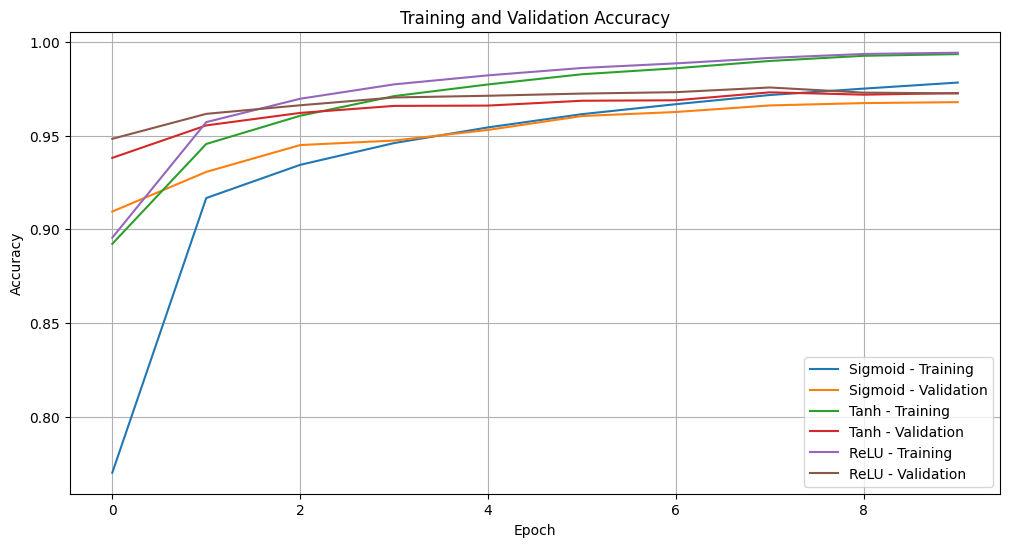

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    history_sigmoid.history["accuracy"],
    label="Sigmoid - Training"
)

plt.plot(
    history_sigmoid.history["val_accuracy"],
    label="Sigmoid - Validation"
)

plt.plot(
    history_tanh.history["accuracy"],
    label="Tanh - Training"
)

plt.plot(
    history_tanh.history["val_accuracy"],
    label="Tanh - Validation"
)

plt.plot(
    history_relu.history["accuracy"],
    label="ReLU - Training"
)

plt.plot(
    history_relu.history["val_accuracy"],
    label="ReLU - Validation"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

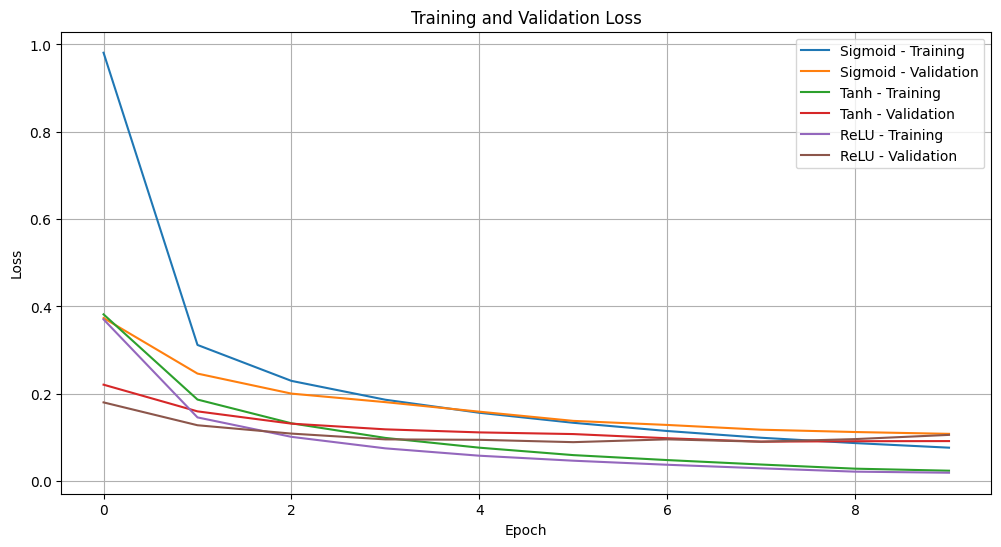

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    history_sigmoid.history["loss"],
    label="Sigmoid - Training"
)

plt.plot(
    history_sigmoid.history["val_loss"],
    label="Sigmoid - Validation"
)

plt.plot(
    history_tanh.history["loss"],
    label="Tanh - Training"
)

plt.plot(
    history_tanh.history["val_loss"],
    label="Tanh - Validation"
)

plt.plot(
    history_relu.history["loss"],
    label="ReLU - Training"
)

plt.plot(
    history_relu.history["val_loss"],
    label="ReLU - Validation"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

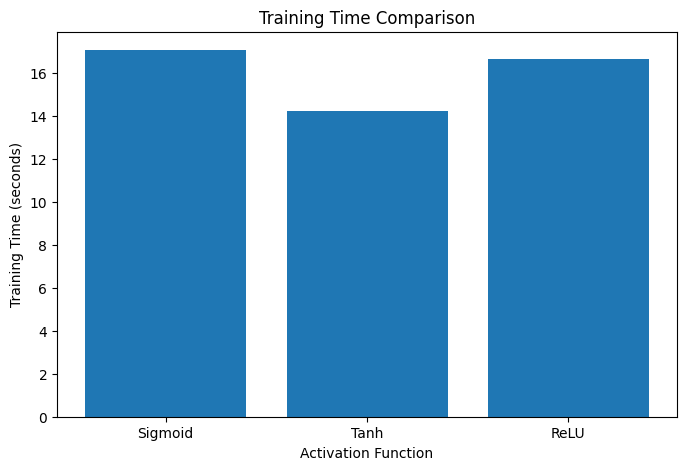

In [ ]:
activation_names = ["Sigmoid", "Tanh", "ReLU"]
training_times = [sigmoid_time, tanh_time, relu_time]

plt.figure(figsize=(8, 5))

plt.bar(activation_names, training_times)

plt.title("Training Time Comparison")
plt.xlabel("Activation Function")
plt.ylabel("Training Time (seconds)")

plt.show()

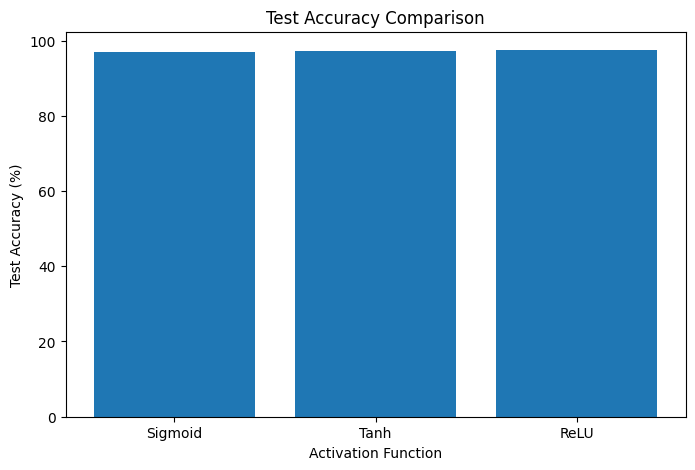

In [ ]:
test_accuracies = [
    sigmoid_test_acc * 100,
    tanh_test_acc * 100,
    relu_test_acc * 100
]

plt.figure(figsize=(8, 5))

plt.bar(activation_names, test_accuracies)

plt.title("Test Accuracy Comparison")
plt.xlabel("Activation Function")
plt.ylabel("Test Accuracy (%)")

plt.show()

In [ ]:
def calculate_gradients(model, x_batch, y_batch):

    with tf.GradientTape() as tape:

        predictions = model(x_batch, training=True)

        loss = tf.keras.losses.sparse_categorical_crossentropy(
            y_batch,
            predictions
        )

        loss = tf.reduce_mean(loss)

    gradients = tape.gradient(
        loss,
        model.trainable_variables
    )

    gradient_magnitudes = []

    for gradient in gradients:
        if gradient is not None:
            gradient_magnitudes.append(
                tf.reduce_mean(tf.abs(gradient)).numpy()
            )
        else:
            gradient_magnitudes.append(0)

    return gradient_magnitudes

In [ ]:
def calculate_gradients(model, x_batch, y_batch):

    with tf.GradientTape() as tape:

        predictions = model(x_batch, training=True)

        loss = tf.keras.losses.sparse_categorical_crossentropy(
            y_batch,
            predictions
        )

        loss = tf.reduce_mean(loss)

    gradients = tape.gradient(
        loss,
        model.trainable_variables
    )

    gradient_magnitudes = []

    for gradient in gradients:
        if gradient is not None:
            gradient_magnitudes.append(
                tf.reduce_mean(tf.abs(gradient)).numpy()
            )
        else:
            gradient_magnitudes.append(0)

    return gradient_magnitudes

In [ ]:
x_gradient = x_train[:128]
y_gradient = y_train[:128]

print("Gradient analysis batch:")
print("Images:", x_gradient.shape)
print("Labels:", y_gradient.shape)

Gradient analysis batch:
Images: (128, 784)
Labels: (128,)


In [ ]:
sigmoid_gradients = calculate_gradients(
    model_sigmoid,
    x_gradient,
    y_gradient
)

tanh_gradients = calculate_gradients(
    model_tanh,
    x_gradient,
    y_gradient
)

relu_gradients = calculate_gradients(
    model_relu,
    x_gradient,
    y_gradient
)

print("Sigmoid gradients:", sigmoid_gradients)
print("\nTanh gradients:", tanh_gradients)
print("\nReLU gradients:", relu_gradients)

Sigmoid gradients: [np.float32(9.7154014e-05), np.float32(0.00057317474), np.float32(0.00052534055), np.float32(0.0010556197), np.float32(0.0019321276), np.float32(0.003742513)]

Tanh gradients: [np.float32(0.00022312428), np.float32(0.0016114835), np.float32(0.0010253876), np.float32(0.0016167747), np.float32(0.0014514667), np.float32(0.0024100002)]

ReLU gradients: [np.float32(0.00031410524), np.float32(0.0027174875), np.float32(0.0012803999), np.float32(0.0021613748), np.float32(0.003857211), np.float32(0.0027859262)]


In [ ]:
layer_names = [
    "Dense 128",
    "Dense 64",
    "Output Dense"
]

print("=" * 70)
print("GRADIENT MAGNITUDES")
print("=" * 70)

for i, layer_name in enumerate(layer_names):

    print(f"\n{layer_name}")

    print(
        f"Sigmoid: {sigmoid_gradients[i * 2]:.8f}"
    )

    print(
        f"Tanh   : {tanh_gradients[i * 2]:.8f}"
    )

    print(
        f"ReLU   : {relu_gradients[i * 2]:.8f}"
    )

GRADIENT MAGNITUDES

Dense 128
Sigmoid: 0.00009715
Tanh   : 0.00022312
ReLU   : 0.00031411

Dense 64
Sigmoid: 0.00052534
Tanh   : 0.00102539
ReLU   : 0.00128040

Output Dense
Sigmoid: 0.00193213
Tanh   : 0.00145147
ReLU   : 0.00385721


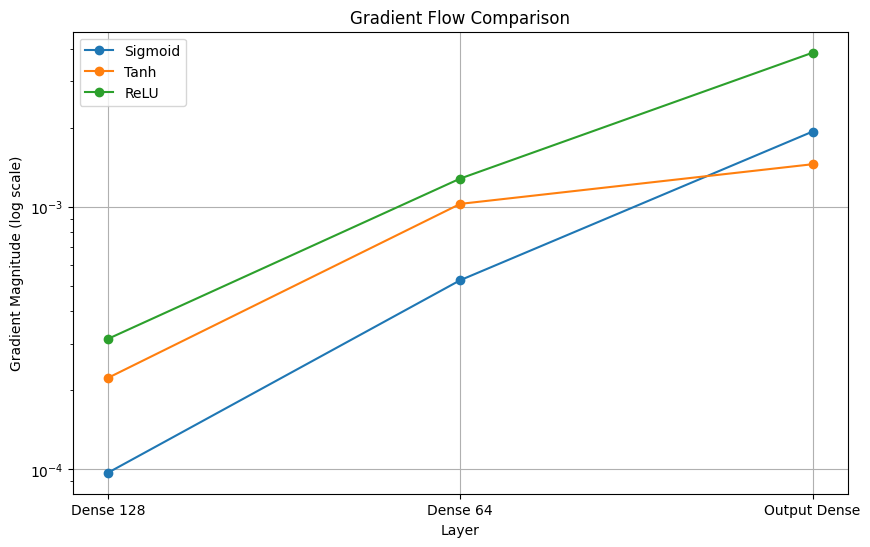

In [ ]:
sigmoid_layer_gradients = [
    sigmoid_gradients[0],
    sigmoid_gradients[2],
    sigmoid_gradients[4]
]

tanh_layer_gradients = [
    tanh_gradients[0],
    tanh_gradients[2],
    tanh_gradients[4]
]

relu_layer_gradients = [
    relu_gradients[0],
    relu_gradients[2],
    relu_gradients[4]
]

plt.figure(figsize=(10, 6))

plt.plot(
    layer_names,
    sigmoid_layer_gradients,
    marker="o",
    label="Sigmoid"
)

plt.plot(
    layer_names,
    tanh_layer_gradients,
    marker="o",
    label="Tanh"
)

plt.plot(
    layer_names,
    relu_layer_gradients,
    marker="o",
    label="ReLU"
)

plt.yscale("log")

plt.title("Gradient Flow Comparison")
plt.xlabel("Layer")
plt.ylabel("Gradient Magnitude (log scale)")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
print("Gradient Flow Analysis")
print("=" * 60)

for i, layer in enumerate(layer_names):

    print(f"\n{layer}")

    print(f"Sigmoid gradient: {sigmoid_layer_gradients[i]:.10f}")
    print(f"Tanh gradient   : {tanh_layer_gradients[i]:.10f}")
    print(f"ReLU gradient   : {relu_layer_gradients[i]:.10f}")

Gradient Flow Analysis

Dense 128
Sigmoid gradient: 0.0000971540
Tanh gradient   : 0.0002231243
ReLU gradient   : 0.0003141052

Dense 64
Sigmoid gradient: 0.0005253406
Tanh gradient   : 0.0010253876
ReLU gradient   : 0.0012803999

Output Dense
Sigmoid gradient: 0.0019321276
Tanh gradient   : 0.0014514667
ReLU gradient   : 0.0038572110
